In [1]:
from pymed import PubMed
import pandas as pd

import matplotlib.pyplot as plt

pubmed = PubMed(tool="MyTool", email="my2@email.address")


In [2]:
open_source = sorted(
    [
        "ACT-seq",
        "ASAP-seq",
        "ASTAR-seq",
        "AbPair",
        "BAR-seq",
        "BART-Seq",
        "BAT-seq",
        "BRIF-seq",
        "BacDrop",
        "CEL-Seq2",
        "CEL-seq",
        "CINEMA-OT",
        "CITE-seq",
        "CLEVER-seq",
        "CLInt-seq",
        "CPA-Perturb-seq",
        "CRISP-seq",
        "CROP-seq",
        "CaRPool-seq",
        "CellTag",
        "CellTagging",
        "CoBATCH",
        "Combi-seq",
        "Convert-seq",
        "CytoSeq",
        "DOGMA-seq",
        "DR-seq",
        "Dip-C",
        "DoTA-seq",
        "DroNC-Seq",
        "Drop-Chip",
        "Drop-seq",
        "Droplet-based scATAC-seq",
        "ECCITE-seq",
        "EasySCI-RNA",
        "FB5P-seq",
        "FFPE-CUTAC",
        "FIN-Seq",
        "FISSEQ",
        "FRISCR",
        "FixNCut",
        "G&T-Seq",
        "GAGE-seq",
        "Geo-seq",
        "Hi-SCL",
        "HyDrop",
        "HyPR-seq",
        "INSTA-seq",
        "INs-seq",
        "ISSAAC-seq",
        "LIBRA-seq",
        "LR-Split-seq",
        "Live-seq",
        "M3-seq",
        "MARS-seq",
        "MARS-seq2.0",
        "MATQ-seq",
        "META-CS",
        "MIX-Seq",
        "MULTI-seq",
        "Microbe-seq",
        "MoonTag/SunTag",
        "Mux-Seq",
        "NEAT-seq",
        "NNT-seq",
        "NanoPARE",
        "PAIso-seq",
        "PERFF-seq",
        "PETRI-seq",
        "PIP-seq",
        "PLAYR",
        "PRDD-seq",
        "Paired-Seq",
        "Patch-seq",
        "Perturb-ATAC",
        "ProBac-seq",
        "Prox-seq",
        "Quartz-Seq",
        "Quartz-Seq2",
        "RABID-seq",
        "RAGE-Seq",
        "RamDA-seq",
        "RevGel-seq",
        "SC3-seq",
        "SCI-LITE",
        "SCITO-seq",
        "SCoPE2",
        "SEC-seq",
        "SIDR-seq",
        "SINC-seq",
        "SMART-seq",
        "SNARE-seq",
        "SPEAR-ATAC",
        "SPLiT-seq",
        "STING-seq",
        "STRT-seq",
        "STRT-seq-2i",
        "SUM-seq",
        "SUPeR-seq",
        "ScarTrace",
        "Sci-Hi-C",
        "Seq-Well",
        "SiC-seq",
        "Simplified-Drop-seq",
        "Slide-seq",
        "Slide-tags",
        "Smart-RRBS",
        "Smart-seq-total",
        "Smart-seq2",
        "SnFFPE-Seq",
        "SnapATAC2",
        "TAP-seq",
        "TARGET-seq",
        "TAS-Seq",
        "TEA-seq",
        "TIP-Seq",
        "TISCC-seq",
        "TM3'seq",
        "TRAPS-seq",
        "TetTCR-SeqHD",
        "Tn5Prime",
        "Trac-looping",
        "TracerSeq",
        "Tuba-seq",
        "Well-Temp-seq",
        "dTn-Seq",
        "dsciATAC-seq",
        "inDrop",
        "iscCOOL-seq",
        "itChIP-seq",
        "mEnrich-seq",
        "mcSCRB-seq",
        "microSPLiT",
        "mtscATAC-seq",
        "nanoSplits",
        "netNMF-sc",
        "sMicro-C",
        "sc paired microRNA-mRNA",
        "sc-GEM",
        "sc-m3c-seq",
        "scBS-seq",
        "scCAT-seq",
        "scCOOL-seq",
        "scCUT&TAG-pro",
        "scChIC-seq",
        "scDam&T-seq",
        "scDamID&T",
        "scGESTALT",
        "scGET-SEQ",
        "scHiC",
        "scISOr-Seq",
        "scM&T-seq",
        "scMNase-seq",
        "scMTseq",
        "scMethylation",
        "scMspJI-seq",
        "scNMT triple omics",
        "scNOMe-seq",
        "scNT-seq",
        "scPLAT",
        "scSNV-Seq",
        "scSNV-seq",
        "scSPLAT",
        "scSPRITE",
        "scTAM-seq",
        "scTEM-seq",
        "scTHS-seq",
        "scTaILoR-seq",
        "scTrio-seq",
        "scWGBS",
        "sci-ATAC-seq",
        "sci-CAR",
        "sci-MET",
        "sci-Plex",
        "sci-RNA-seq",
        "sci-RNA-seq3",
        "sci-fate",
        "sci-fate",
        "sciMETv2",
        "scifi-RNA-seq",
        "smRandom-seq",
        "sn-m3C-seq",
        "snPATHO-Seq",
        "snhmC-seq",
        "snmC-seq",
        "snmC-seq2",
        "snmCAT-seq",
        "vDip-C",
        "viscRNA-seq",
        "yscRNA-SEQ",
    ]
)

In [3]:
import os
import json
import time
import requests

QUERY_LOG_FILE = "pubmed_queries.txt"  # Stores all executed queries
RESULTS_FILE = "pubmed_results.csv"    # Stores all article results

def load_previous_queries():
    """Load previously executed queries from the text file."""
    if os.path.exists(QUERY_LOG_FILE):
        with open(QUERY_LOG_FILE, "r") as f:
            return set(line.strip() for line in f.readlines())
    return set()

def save_new_query(query):
    """Append a single new query to the text file."""
    with open(QUERY_LOG_FILE, "a") as f:
        f.write(query + "\n")

def load_results():
    """Load previously saved results from disk."""
    if os.path.exists(RESULTS_FILE):
        return pd.read_csv(RESULTS_FILE)
    return pd.DataFrame()

def save_results(df):
    """Save the DataFrame to disk in CSV format."""
    df.to_csv(RESULTS_FILE, index=False)

def fetch_articles_df(pubmed_queries):
    """Fetch articles from PubMed, avoid redundant queries, and store results persistently."""
    previous_queries = load_previous_queries()
    df_existing = load_results()

    # Separate new and old queries
    new_queries = [q for q in pubmed_queries if q not in previous_queries]
    old_queries = [q for q in pubmed_queries if q in previous_queries]

    # If no new queries, return existing results for old queries
    if not new_queries:
        print("All queries have already been executed. Loading saved results.")
        return df_existing[df_existing["matched_keywords"].apply(lambda x: any(q in x for q in old_queries))]

    for i, pubmed_query in enumerate(new_queries):
        print(f"Query {i + 1}/{len(new_queries)}: {pubmed_query}")

        try:
            # Introduce a small delay to avoid rate limits
            time.sleep(1)  

            response = pubmed.query(pubmed_query, max_results=99999)

            # Check if response is valid JSON
            if isinstance(response, requests.Response):
                if response.status_code != 200:
                    print(f"Warning: Non-200 response for query '{pubmed_query}' (Status: {response.status_code})")
                    print(f"Response Text: {response.text[:500]}")
                    continue  # Skip this query and move to next

                # Try parsing JSON and identify bad characters
                try:
                    response_json = response.json()
                except json.JSONDecodeError as e:
                    print("\n--- JSON Decode Error ---")
                    print(f"Query: {pubmed_query}")
                    print(f"Error message: {e}")
                    
                    # Get the problematic character position
                    error_pos = e.pos  
                    raw_response = response.text

                    # Print the full response if short, else truncate
                    print(f"Raw response (first 500 chars): {raw_response[:500]}")
                    
                    # Highlight the exact character causing the error
                    if error_pos < len(raw_response):
                        print(f"Offending character at position {error_pos}: '{raw_response[error_pos]}' (ASCII: {ord(raw_response[error_pos])})")
                    
                    print("-------------------------\n")
                    continue  # Skip this query and proceed

            else:
                # If response isn't a requests object, ensure it's iterable
                results = list(response)

        except Exception as e:
            print(f"Unexpected error for query '{pubmed_query}': {e}")
            continue  # Skip this query and proceed

        articles_dict = {}

        for article in results:
            article_dict = article.toDict()
            pubmed_id = article_dict["pubmed_id"]

            if pubmed_id in articles_dict:
                articles_dict[pubmed_id]["matched_keywords"].append(pubmed_query)
            else:
                article_dict["matched_keywords"] = [pubmed_query]
                articles_dict[pubmed_id] = article_dict

        # Convert new results to DataFrame
        df_new = pd.DataFrame(articles_dict.values())

        if not df_new.empty:
            # Remove bioRxiv entries
            df_new = df_new[~df_new["journal"].str.contains("bioRxiv", case=False, na=False)]
            df_new["publication_date"] = pd.to_datetime(df_new["publication_date"], errors="coerce")

            # Merge with existing data, ensuring no duplicates
            df_existing = pd.concat([df_existing, df_new], ignore_index=True).drop_duplicates(subset=["pubmed_id"])
            save_results(df_existing)  # Save **immediately after every query**
            save_new_query(pubmed_query)  # Save the query **immediately after every query**

    # Return results for both new and old queries
    return df_existing[df_existing["matched_keywords"].apply(lambda x: any(q in x for q in pubmed_queries))]


In [4]:
df_open_source = fetch_articles_df(open_source)
df_open_source["query_category"] = "Open Source"

pubmed_queries = ["bio-rad AND single-cell", "biorad AND single-cell"]
df_biorad = fetch_articles_df(pubmed_queries)
df_biorad["query_category"] = "Bio-Rad"

pubmed_queries = ["10x genomics"]
df_10x = fetch_articles_df(pubmed_queries)
df_10x["query_category"] = "10x Genomics"

# pubmed_queries = ["10x genomics AND RNA"]
# df_10x_rna = fetch_articles_df(pubmed_queries)
# df_10x_rna["query_category"] = "10x Genomics scRNA-seq"

# pubmed_queries = ["10x genomics AND ATAC"]
# df_10x_atac = fetch_articles_df(pubmed_queries)
# df_10x_atac["query_category"] = "10x Genomics scATAC-seq"

# pubmed_queries = ["10x genomics AND multiome"]
# df_10x_multiome = fetch_articles_df(pubmed_queries)
# df_10x_multiome["query_category"] = "10x Genomics multiome"

# pubmed_queries = ["RNA-seq"]
# df_rnaseq = fetch_articles_df(pubmed_queries)
# df_rnaseq["query_category"] = "RNA-seq"

# pubmed_queries = ["ATAC-seq OR DNAse-seq OR CHIP-seq"]
# df_atac = fetch_articles_df(pubmed_queries)
# df_atac["query_category"] = "ATAC-seq/DNase-seq"

df_combined = pd.concat(
    [df_open_source, df_biorad, df_10x], ignore_index=True
)

Query 1/17: Convert-seq
Query 2/17: EasySCI-RNA
Query 3/17: HyDrop
Unexpected error for query 'HyDrop': Invalid control character at: line 1 column 105 (char 104)
Query 4/17: INSTA-seq
Query 5/17: MARS-seq2.0
Query 6/17: NNT-seq
Query 7/17: STING-seq
Query 8/17: SUM-seq
Query 9/17: Simplified-Drop-seq
Query 10/17: SnFFPE-Seq
Query 11/17: TM3'seq
Query 12/17: sMicro-C
Query 13/17: sc-m3c-seq
Query 14/17: scDamID&T
Query 15/17: scNMT triple omics
Query 16/17: sn-m3C-seq
Query 17/17: snhmC-seq
All queries have already been executed. Loading saved results.
All queries have already been executed. Loading saved results.


In [5]:
df_combined

,pubmed_id,title,abstract,keywords,journal,publication_date,authors,methods,conclusions,results,...,doi,xml,matched_keywords,isbn,language,publication_type,sections,publisher,publisher_location,query_category
0,35468210\n34185076\n24120142\n18772890\n247264...,MEOX2 homeobox gene promotes growth of maligna...,Glioblastoma (GBM) is an aggressive tumor that...,"['ERK signaling', 'MEOX2', 'cerebral organoids...",Neuro-oncology,2022-04-26,"[{'lastname': 'Schönrock', 'firstname': 'Anna'...",NaN,NaN,MEOX2 enhanced ERK signaling through a feed-fo...,...,10.1093/neuonc/noac110\n10.3390/cancers1310245...,<Element 'PubmedArticle' at 0x134166610>,['ACT-seq'],NaN,NaN,NaN,NaN,NaN,NaN,Open Source
1,34879231\n28991892\n29632302\n13167245\n262695...,A transcriptional rheostat couples past activi...,Animals traversing different environments enco...,"['Act-seq', 'adaptation', 'functional imaging'...",Cell,2021-12-09,"[{'lastname': 'Tsukahara', 'firstname': 'Tatsu...",NaN,NaN,NaN,...,10.1016/j.cell.2021.11.022,<Element 'PubmedArticle' at 0x1344a2570>,['ACT-seq'],NaN,NaN,NaN,NaN,NaN,NaN,Open Source
2,34863284\n24631868\n29395069\n31267065\n249051...,Concurrent mapping of multiple epigenetic mark...,Genome-wide profiling of epigenetic marks is a...,"['ACT-seq', 'Co-enrichment', 'Co-occupancy', '...",Cell & bioscience,2021-12-06,"[{'lastname': 'Carter', 'firstname': 'Benjamin...",NaN,NaN,We concurrently profiled pairs of two epigenet...,...,10.1186/s13578-021-00711-4\n10.1016/j.bbagrm.2...,<Element 'PubmedArticle' at 0x135c259e0>,['ACT-seq'],NaN,NaN,NaN,NaN,NaN,NaN,Open Source
3,32873803,Author Correction: Mapping histone modificatio...,An amendment to this paper has been published ...,[],Nature communications,2020-09-03,"[{'lastname': 'Carter', 'firstname': 'Benjamin...",NaN,NaN,NaN,...,10.1038/s41467-020-18309-8,<Element 'PubmedArticle' at 0x135e126b0>,['ACT-seq'],NaN,NaN,NaN,NaN,NaN,NaN,Open Source
4,32272058\n20935642\n28991892\n15694307\n222037...,Transcriptional and Spatial Resolution of Cell...,The habenula complex is appreciated as a criti...,"['Act-seq', 'Habenula', 'HiPlex', 'SCENIC', 'S...",Neuron,2020-04-10,"[{'lastname': 'Hashikawa', 'firstname': 'Yoshi...",NaN,NaN,NaN,...,10.1016/j.neuron.2020.03.011,<Element 'PubmedArticle' at 0x135e11490>,['ACT-seq'],NaN,NaN,NaN,NaN,NaN,NaN,Open Source
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2577,743594,Mutation and disease in man.,Efforts to evaluate the burden of genetic dise...,[],Canadian journal of genetics and cytology. Jou...,1978-09-01 00:00:00,"[{'lastname': 'Neel', 'firstname': 'J V', 'ini...",NaN,NaN,NaN,...,10.1139/g78-033,<Element 'PubmedArticle' at 0x1569a9260>,['10x genomics'],NaN,NaN,NaN,NaN,NaN,NaN,10x Genomics
2578,178898\n4352888\n4355371\n4355853\n4355929\n43...,Use of alkaline sucrose gradients in a zonal r...,We have attempted to distinguish integrated an...,[],Journal of virology,1976-05-01 00:00:00,"[{'lastname': 'Varmus', 'firstname': 'H E', 'i...",NaN,NaN,NaN,...,10.1128/JVI.18.2.574-585.1976,<Element 'PubmedArticle' at 0x1569b4590>,['10x genomics'],NaN,NaN,NaN,NaN,NaN,NaN,10x Genomics
2579,170417\n1054828\n6057678\n163973\n164022\n4116...,Kinetics of murine type C virus-specific DNA s...,Replicating transforming functions of Rauscher...,[],Journal of virology,1975-10-01 00:00:00,"[{'lastname': 'Lovinger', 'firstname': 'G G', ...",NaN,NaN,NaN,...,10.1128/JVI.16.4.824-831.1975,<Element 'PubmedArticle' at 0x1569c2020>,['10x genomics'],NaN,NaN,NaN,NaN,NaN,NaN,10x Genomics
2580,4626505\n4950060\n10970178\n16591089\n4920090\...,A second transport system for L-arabinose in E...,Escherichia coli B/r possesses two active tran...,[],Journal of bacteriology,1972-08-01 00:00:00,"[{'lastname': 'Brown', 'firstname': 'C E', 'in...",NaN,NaN,NaN,...,10.1128/jb.111.2.606-613.1972,<Element 'PubmedArticle' at 0x1569cf8d0>,['10x genomics'],NaN,NaN,NaN,NaN,NaN,NaN,10x Genomics


In [6]:
df = df_combined.copy()

In [7]:
df.columns

Index(['pubmed_id', 'title', 'abstract', 'keywords', 'journal',
       'publication_date', 'authors', 'methods', 'conclusions', 'results',
       'copyrights', 'doi', 'xml', 'matched_keywords', 'isbn', 'language',
       'publication_type', 'sections', 'publisher', 'publisher_location',
       'query_category'],
      dtype='object')

In [8]:
df["publication_date"] = pd.to_datetime(df["publication_date"], format="mixed")

df = df[df["publication_date"] >= "2011-01-01"]

In [9]:
mask = ~((df["matched_keywords"].apply(lambda x: "inDrop" in x)) & 
         (df["publication_date"] < "2015-01-01"))

df = df[mask]
mask = ~((df["matched_keywords"].apply(lambda x: "bio-rad AND single-cell" in x)) & 
         (df["publication_date"] < "2017-01-01"))

df = df[mask]
keyword_counts = df.explode("matched_keywords")["matched_keywords"].value_counts()

print(keyword_counts.to_string())


matched_keywords
['10x genomics']                    514
['10x genomics AND single-cell']    397
['CITE-seq']                        230
['10x genomics AND RNA']            121
['Smart-seq2']                      107
['SMART-seq']                        78
['Drop-seq']                         77
['Patch-seq']                        65
['scHiC']                            36
['Slide-seq']                        32
['BAR-seq']                          31
['Dip-C']                            27
['bio-rad AND single-cell']          19
['LIBRA-seq']                        17
['TARGET-seq']                       16
['SCoPE2']                           15
['CROP-seq']                         15
['inDrop']                           15
['scBS-seq']                         15
['CEL-Seq2']                         15
['Seq-Well']                         14
['FISSEQ']                           13
['CEL-seq']                          13
['10x genomics AND ATAC']            12
['MULTI-seq']          

/var/folders/p_/flb84jgs2_jbb5_gnn1645jw0000gn/T/ipykernel_90859/2764106404.py:3: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  monthly_counts = df.resample("Y", on="publication_date").size()


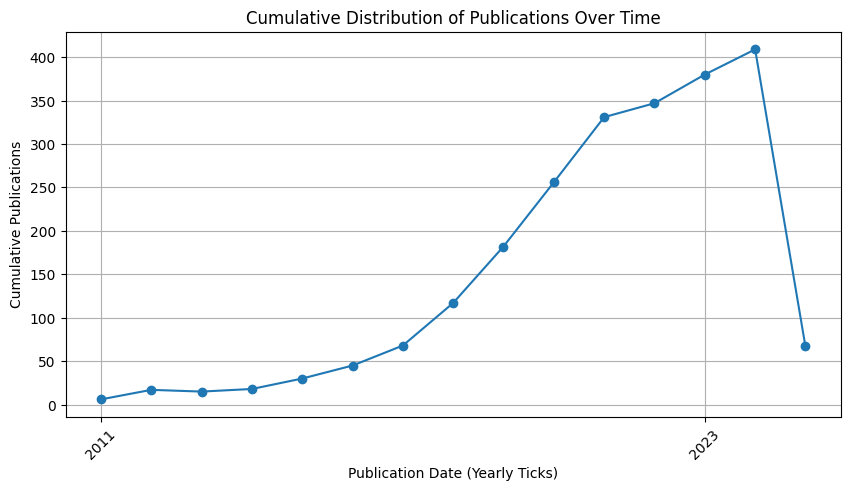

In [10]:
df["publication_date"] = pd.to_datetime(df["publication_date"])

monthly_counts = df.resample("Y", on="publication_date").size()

plt.figure(figsize=(10, 5))
plt.plot(monthly_counts.index, monthly_counts.values, marker="o", linestyle="-")

plt.xticks(
    monthly_counts.index[::12], monthly_counts.index.strftime("%Y")[::12], rotation=45
)

plt.xlabel("Publication Date (Yearly Ticks)")
plt.ylabel("Cumulative Publications")
plt.title("Cumulative Distribution of Publications Over Time")
plt.grid(True)
plt.show()


/var/folders/p_/flb84jgs2_jbb5_gnn1645jw0000gn/T/ipykernel_90859/1757428990.py:3: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_counts = df.resample("M", on="publication_date").size().cumsum()


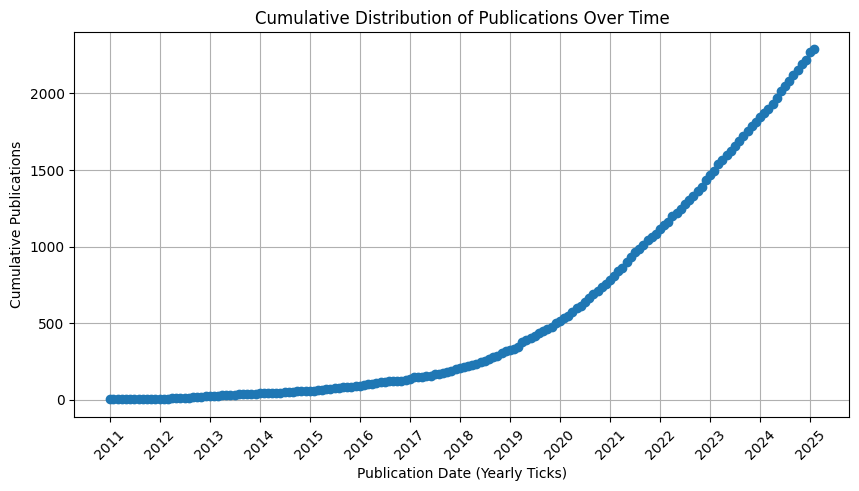

In [11]:
df["publication_date"] = pd.to_datetime(df["publication_date"])

monthly_counts = df.resample("M", on="publication_date").size().cumsum()

plt.figure(figsize=(10, 5))
plt.plot(monthly_counts.index, monthly_counts.values, marker="o", linestyle="-")

plt.xticks(
    monthly_counts.index[::12], monthly_counts.index.strftime("%Y")[::12], rotation=45
)

plt.xlabel("Publication Date (Yearly Ticks)")
plt.ylabel("Cumulative Publications")
plt.title("Cumulative Distribution of Publications Over Time")
plt.grid(True)
plt.show()


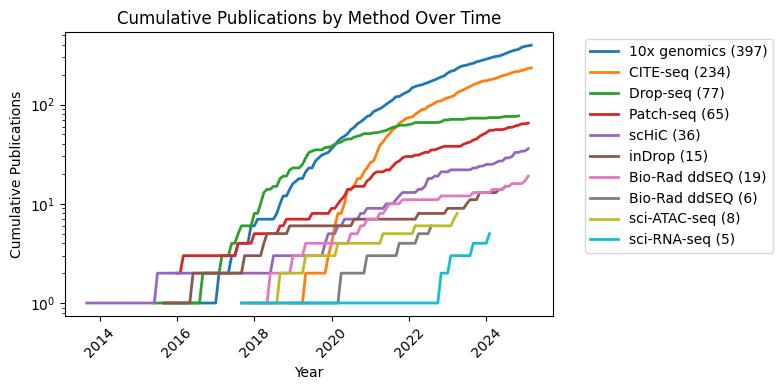

In [12]:
methods_of_interest = [
    "10x genomics AND single-cell",
    "CITE-seq",
    "Drop-seq",
    "Patch-seq",
    "scHiC",
    "inDrop",
    "bio-rad AND single-cell",
    "biorad AND single-cell",
    "sci-ATAC-seq",
    "sci-RNA-seq"
]

smart_seq = ["Smart-seq2", "SMART-seq"]

df_exploded = df.explode("matched_keywords")

mask_smart = df_exploded["matched_keywords"].isin(smart_seq)
df_exploded.loc[mask_smart, "matched_keywords"] = "Smart-seq (combined)"

plt.figure(figsize=(8, 4))

plotted_data = pd.Series(False, index=df_exploded.index)

for method in methods_of_interest:
    method_mask = df_exploded["matched_keywords"].str.contains(method, regex=False, na=False)
    plotted_data |= method_mask
    method_data = df_exploded[method_mask]
    if not method_data.empty:
        monthly_counts = method_data.groupby(pd.Grouper(key="publication_date", freq="ME")).size().cumsum()
        label = method.replace("10x genomics AND single-cell", "10x genomics").replace("bio-rad AND single-cell", "Bio-Rad ddSEQ").replace("biorad AND single-cell", "Bio-Rad ddSEQ")
        final_count = monthly_counts.iloc[-1]
        plt.plot(monthly_counts.index, monthly_counts.values, label=f"{label} ({final_count})", marker="", linewidth=2)

method_mask_smart = df_exploded["matched_keywords"] == "Smart-seq (combined)"
method_data_smart = df_exploded[method_mask_smart]
if not method_data_smart.empty:
    monthly_counts_smart = method_data_smart.groupby(pd.Grouper(key="publication_date", freq="ME")).size().cumsum()
    final_count_smart = monthly_counts_smart.iloc[-1]
    plt.plot(monthly_counts_smart.index, monthly_counts_smart.values, label=f"Smart-seq (combined) ({final_count_smart})", marker="", linewidth=2)

plt.xticks(rotation=45)
plt.xlabel("Year")
plt.ylabel("Cumulative Publications")
plt.title("Cumulative Publications by Method Over Time")
plt.yscale('log')
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.savefig("cumulative_publications_by_method.svg")
plt.show()

In [13]:
df_exploded

,pubmed_id,title,abstract,keywords,journal,publication_date,authors,methods,conclusions,results,...,doi,xml,matched_keywords,isbn,language,publication_type,sections,publisher,publisher_location,query_category
0,35468210\n34185076\n24120142\n18772890\n247264...,MEOX2 homeobox gene promotes growth of maligna...,Glioblastoma (GBM) is an aggressive tumor that...,"['ERK signaling', 'MEOX2', 'cerebral organoids...",Neuro-oncology,2022-04-26,"[{'lastname': 'Schönrock', 'firstname': 'Anna'...",NaN,NaN,MEOX2 enhanced ERK signaling through a feed-fo...,...,10.1093/neuonc/noac110\n10.3390/cancers1310245...,<Element 'PubmedArticle' at 0x134166610>,['ACT-seq'],NaN,NaN,NaN,NaN,NaN,NaN,Open Source
1,34879231\n28991892\n29632302\n13167245\n262695...,A transcriptional rheostat couples past activi...,Animals traversing different environments enco...,"['Act-seq', 'adaptation', 'functional imaging'...",Cell,2021-12-09,"[{'lastname': 'Tsukahara', 'firstname': 'Tatsu...",NaN,NaN,NaN,...,10.1016/j.cell.2021.11.022,<Element 'PubmedArticle' at 0x1344a2570>,['ACT-seq'],NaN,NaN,NaN,NaN,NaN,NaN,Open Source
2,34863284\n24631868\n29395069\n31267065\n249051...,Concurrent mapping of multiple epigenetic mark...,Genome-wide profiling of epigenetic marks is a...,"['ACT-seq', 'Co-enrichment', 'Co-occupancy', '...",Cell & bioscience,2021-12-06,"[{'lastname': 'Carter', 'firstname': 'Benjamin...",NaN,NaN,We concurrently profiled pairs of two epigenet...,...,10.1186/s13578-021-00711-4\n10.1016/j.bbagrm.2...,<Element 'PubmedArticle' at 0x135c259e0>,['ACT-seq'],NaN,NaN,NaN,NaN,NaN,NaN,Open Source
3,32873803,Author Correction: Mapping histone modificatio...,An amendment to this paper has been published ...,[],Nature communications,2020-09-03,"[{'lastname': 'Carter', 'firstname': 'Benjamin...",NaN,NaN,NaN,...,10.1038/s41467-020-18309-8,<Element 'PubmedArticle' at 0x135e126b0>,['ACT-seq'],NaN,NaN,NaN,NaN,NaN,NaN,Open Source
4,32272058\n20935642\n28991892\n15694307\n222037...,Transcriptional and Spatial Resolution of Cell...,The habenula complex is appreciated as a criti...,"['Act-seq', 'Habenula', 'HiPlex', 'SCENIC', 'S...",Neuron,2020-04-10,"[{'lastname': 'Hashikawa', 'firstname': 'Yoshi...",NaN,NaN,NaN,...,10.1016/j.neuron.2020.03.011,<Element 'PubmedArticle' at 0x135e11490>,['ACT-seq'],NaN,NaN,NaN,NaN,NaN,NaN,Open Source
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2370,23185431\n1408825\n10508514\n4003065\n22474603...,Novel MeCP2 isoform-specific antibody reveals ...,Rett Syndrome (RTT) is a severe neurological d...,[],PloS one,2012-11-28,"[{'lastname': 'Zachariah', 'firstname': 'Robby...",NaN,NaN,NaN,...,10.1371/journal.pone.0049763,<Element 'PubmedArticle' at 0x1562314e0>,['10x genomics'],NaN,NaN,NaN,NaN,NaN,NaN,10x Genomics
2371,23150898\n13751193\n11931686\n20031536\n206865...,Evaluation of seven common lipid associated lo...,"Genome wide association studies (GWAS), mostly...",[],Lipids in health and disease,2012-11-16,"[{'lastname': 'Rafiq', 'firstname': 'Sajjad', ...",NaN,NaN,We replicated five of the 7 main effect associ...,...,10.1186/1476-511X-11-155\n10.1038/nature09270\...,<Element 'PubmedArticle' at 0x156250590>,['10x genomics'],NaN,NaN,NaN,NaN,NaN,NaN,10x Genomics
2372,22799219,[Construction and characterization of aroA del...,We constructed Pasteurella multocida strain C5...,[],Wei sheng wu xue bao = Acta microbiologica Sinica,2012-07-18,"[{'lastname': 'Guo', 'firstname': 'Dongchun', ...",NaN,The virulence of aroA mutant strain of P. mult...,The aroA mutant strain of P. multocida C51-17 ...,...,NaN,<Element 'PubmedArticle' at 0x1562705e0>,['10x genomics'],NaN,NaN,NaN,NaN,NaN,NaN,10x Genomics
2373,21789897,Significant association of caveolin-1 genotype...,Many articles have reported the caveolin-1 gen...,[],The Chinese journal of physiology,2011-07-28,"[{'lastname': 'Bau', 'firstname': 'Da-Tian', '...",NaN,NaN,NaN,...,10.4077/cjp.2011.amm009,<Element 'PubmedArticle' at 0x1562ca480>,['10x genomics'],NaN,NaN,NaN,N